Iteration 20: SSE = 145.8712
Iteration 40: SSE = 140.8302
Iteration 60: SSE = 139.9931
Iteration 80: SSE = 139.8427
Iteration 100: SSE = 139.8269

PSO results
Best SSE: 139.8269
Silhouette score: 0.4594

K-means results
SSE: 139.8205
Silhouette score: 0.4599


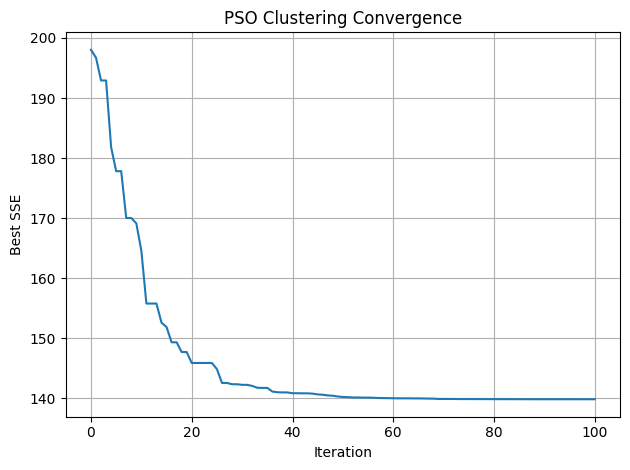

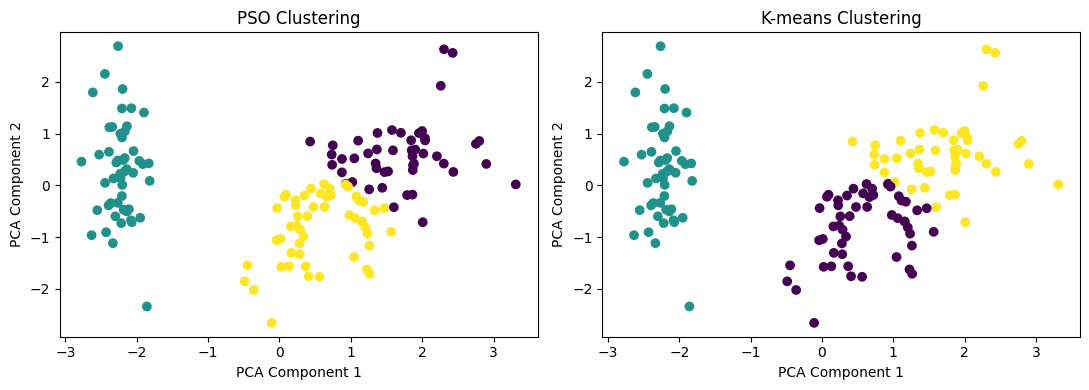

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Load and scale the dataset
data = load_iris()
X = StandardScaler().fit_transform(data.data)

N, D = X.shape
K = 3

# 2. PSO parameters
particles = 30
iterations = 100
w = 0.7
c1 = 1.5
c2 = 1.5

rng = np.random.default_rng(42)

lower = X.min(axis=0)
upper = X.max(axis=0)

# Each particle contains K cluster centers
position = np.array([
    X[rng.choice(N, K, replace=False)]
    for _ in range(particles)
])

velocity = rng.normal(0, 0.1, position.shape)

# 3. Fitness function: minimize within-cluster SSE
def fitness(centers):
    distances = np.sum(
        (X[:, None, :] - centers[None, :, :]) ** 2,
        axis=2
    )
    return np.sum(np.min(distances, axis=1))

# 4. Initialize personal and global best
pbest = position.copy()
pbest_score = np.array([fitness(p) for p in position])

best_index = np.argmin(pbest_score)
gbest = pbest[best_index].copy()
gbest_score = pbest_score[best_index]

history = [gbest_score]

# 5. Main PSO loop
for t in range(iterations):

    r1 = rng.random(position.shape)
    r2 = rng.random(position.shape)

    # Update velocity
    velocity = (
        w * velocity
        + c1 * r1 * (pbest - position)
        + c2 * r2 * (gbest - position)
    )

    # Update position
    position = np.clip(
        position + velocity, lower, upper
    )

    # Evaluate each particle
    scores = np.array([fitness(p) for p in position])

    # Update personal best
    improved = scores < pbest_score
    pbest[improved] = position[improved]
    pbest_score[improved] = scores[improved]

    # Update global best
    best_index = np.argmin(pbest_score)

    if pbest_score[best_index] < gbest_score:
        gbest = pbest[best_index].copy()
        gbest_score = pbest_score[best_index]

    history.append(gbest_score)

    if (t + 1) % 20 == 0:
        print(f"Iteration {t+1}: SSE = {gbest_score:.4f}")

# 6. Assign points to the best centers
distances = np.sum(
    (X[:, None, :] - gbest[None, :, :]) ** 2,
    axis=2
)
labels = np.argmin(distances, axis=1)

print("\nPSO results")
print("Best SSE:", round(gbest_score, 4))
print("Silhouette score:",
      round(silhouette_score(X, labels), 4))

# 7. Compare with K-means
km = KMeans(n_clusters=K, random_state=42, n_init=10)
km_labels = km.fit_predict(X)

print("\nK-means results")
print("SSE:", round(km.inertia_, 4))
print("Silhouette score:",
      round(silhouette_score(X, km_labels), 4))

# 8. Plot convergence
plt.figure()
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best SSE")
plt.title("PSO Clustering Convergence")
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Visualize clusters in 2D using PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=labels, cmap="viridis"
)
axes[0].set_title("PSO Clustering")

axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=km_labels, cmap="viridis"
)
axes[1].set_title("K-means Clustering")

for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")

plt.tight_layout()
plt.show()
